In [18]:
import os
import numpy as np
import tensorflow as tf
import keras
from keras import layers
from datasets import load_dataset
os.environ["KERAS_BACKEND"] = "jax"

In [2]:
from datasets import load_dataset

ds = load_dataset("fancyzhx/ag_news")

In [3]:
print(ds)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


In [4]:
# labels with possible values: World (0), Sports (1), Business (2), Sci/Tech (3).
# Dividiamo il dataset con la funzione "train_test_split" per prendere il 20% dei dati di training
# e usarli come dati di Validation
split = ds["train"].train_test_split(
    test_size=0.2,                      # prendiamo il 20% del dataset
    seed=42,                            # fissiamo un seed per prendere valori random
    stratify_by_column="label"          # manteniamo la stessa "spalmatura" utilizzata per label
)

ds_training = split["train"]
ds_validation = split["test"]
ds_test = ds["test"]

print("----Training Dataset----")
print(ds_training)
print("----Validation Dataset----")
print(ds_validation)
print("----Test Dataset----")
print(ds_test)

print("\nLabels:")
print(ds["train"].features["label"].names)



----Training Dataset----
Dataset({
    features: ['text', 'label'],
    num_rows: 96000
})
----Validation Dataset----
Dataset({
    features: ['text', 'label'],
    num_rows: 24000
})
----Test Dataset----
Dataset({
    features: ['text', 'label'],
    num_rows: 7600
})

Labels:
['World', 'Sports', 'Business', 'Sci/Tech']


In [ ]:
# Convertiamo le parole in numeri per darli in pasto alla rete neurale
# per farlo utilizziamo layers.TextVectorization

max_tokens = 20_000
sequence_length = 200

vectorizer = layers.TextVectorization(
    max_tokens = max_tokens,
    standardize = "lower_and_strip_punctuation",
    split = "whitespace",
    output_mode="int",
    output_sequence_length = sequence_length
)


# Convertiamo in un dataset Tensorflow per migliorare il run del metodo .adapt()
tf_train_texts = tf.data.Dataset.from_tensor_slices(
    list(ds_training["text"])
)

# Raggruppiamo la lista di elementi in batches
tf_train_texts = tf_train_texts.batch(1024)

# Genera il vocabolario convertendo una parola con un intero
vectorizer.adapt(tf_train_texts)         
vocabulary = vectorizer.get_vocabulary() 



<class 'tensorflow.python.data.ops.from_tensor_slices_op._TensorSliceDataset'>
Dimensione vocabolario: 20000
['', '[UNK]', np.str_('the'), np.str_('to'), np.str_('a'), np.str_('of'), np.str_('in'), np.str_('and'), np.str_('on'), np.str_('for'), np.str_('39s'), np.str_('that'), np.str_('with'), np.str_('as'), np.str_('at'), np.str_('its'), np.str_('is'), np.str_('new'), np.str_('by'), np.str_('said')]


In [23]:
article = ds_training["text"][0]
print(article)

Circuit City to stop selling T-Mobile Circuit City Stores Inc. said it will halt sales of T-Mobile USA mobile phones and give the business solely to Verizon Wireless, its other current mobile-phone partner, which will open in-store sales counters.


In [32]:
# Converto i dataset HuggingFace in dataset Tensorflow
# I dataset avranno quindi l'associazione testo -> etichetta


tf_training_ds = tf.data.Dataset.from_tensor_slices((
    list(ds_training["text"]),
    np.asarray(ds_training["label"], dtype="int32")
))

print("TensorFlow Training Dataset created!")

tf_validation_ds = tf.data.Dataset.from_tensor_slices((
    list(ds_validation["text"]),
    np.asarray(ds_validation["label"], dtype="int32")
))

print("TensorFlow Validation Dataset created!")

tf_test_ds = tf.data.Dataset.from_tensor_slices((
    list(ds_test["text"]),
    np.asarray(ds_test["label"], dtype="int32")
))

print("TensorFlow Test Dataset created!")


TensorFlow Training Dataset created!
TensorFlow Validation Dataset created!
TensorFlow Test Dataset created!


In [33]:
# Creazione dei batches


batch_size = 128
def batch_creation(Dataset):
    
    ds_batch = Dataset.shuffle(20_000, seed=42).batch(batch_size)
    return ds_batch

for texts, labels in tf_training_ds.take(1):
    print("Forma testi:", texts.shape)
    print("Forma etichette:", labels.shape)

tf_training_ds = batch_creation(tf_training_ds)
tf_validation_ds = tf_validation_ds.batch(batch_size)
tf_test_ds = tf_test_ds.batch(batch_size)

for texts, labels in tf_training_ds.take(1):
    print("Forma testi:", texts.shape)
    print("Forma etichette:", labels.shape)


Forma testi: ()
Forma etichette: ()
Forma testi: (128,)
Forma etichette: (128,)


In [ ]:
# Applicaizone del Vectorizer ai batch

tf_sequence_train_ds = tf_training_ds.map(
    lambda texts, labels: ( vectorizer(texts), labels ),
    num_parallel_calls= tf.data.AUTOTUNE              #Parallelizzazione vectorizer(texts) 
                                                      #demandando a TF il numero di batch in parallelo
)

tf_sequence_val_ds = tf_validation_ds.map(
    lambda texts, labels: ( vectorizer(texts), labels ),
    num_parallel_calls= tf.data.AUTOTUNE
)

tf_sequence_test_ds = tf_test_ds.map(
    lambda texts, labels: ( vectorizer(texts), labels ),
    num_parallel_calls= tf.data.AUTOTUNE
)

for tokens, label in tf_sequence_test_ds.take(1):
    print("Forma Tokens: ", tokens.shape)
    print("Forma Label: ", label.shape)

# Tokens: batch da 128 elementi, ognuno contenente 200 ID numerici interi


Forma Tokens:  (128, 200)
Forma Label:  (128,)


In [38]:
# l'Embedding ora deve trasformare ogni ID numerico intero in un vettore di float

input = keras.Input(
    shape=(200,),
    dtype="int32"
)

x = layers.Embedding(
    input_dim=20_000,
    output_dim=64,
    mask_zero=True,
    name="work_embedding"
)(input)

y = layers.Bidirectional(
    layers.LSTM(64),
    name="bidirectional_lstm"
)(x)

z = layers.Dropout(
    0.5,
    name="dropout"
)(y)

output = layers.Dense(
    4,
    activation="softmax",
    name="classification"
)(z)

model = keras.Model(
    inputs = input,
    outputs=output,
    name="ag_news_classifier"
)

model.summary()

Model: "ag_news_classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ work_embedding      │ (None, 200, 64)   │  1,280,000 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 200)       │          0 │ input_layer_2[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_lstm  │ (None, 128)       │     66,048 │ work_embedding[0… │
│ (Bidirectional)     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bidirectional_ls… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classification      │ (None, 4)         │        516 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,346,564 (5.14 MB)

 Trainable params: 1,346,564 (5.14 MB)

 Non-trainable params: 0 (0.00 B)

In [40]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    tf_sequence_train_ds,
    validation_data=tf_sequence_val_ds,
    epochs=20,
    callbacks=[early_stopping]
)

Epoch 1/20


/opt/miniconda3/envs/ai_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


750/750 ━━━━━━━━━━━━━━━━━━━━ 159s 211ms/step - accuracy: 0.8694 - loss: 0.3775 - val_accuracy: 0.9164 - val_loss: 0.2529
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 163s 217ms/step - accuracy: 0.9333 - loss: 0.2044 - val_accuracy: 0.9151 - val_loss: 0.2568
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 153s 204ms/step - accuracy: 0.9447 - loss: 0.1644 - val_accuracy: 0.9108 - val_loss: 0.2720


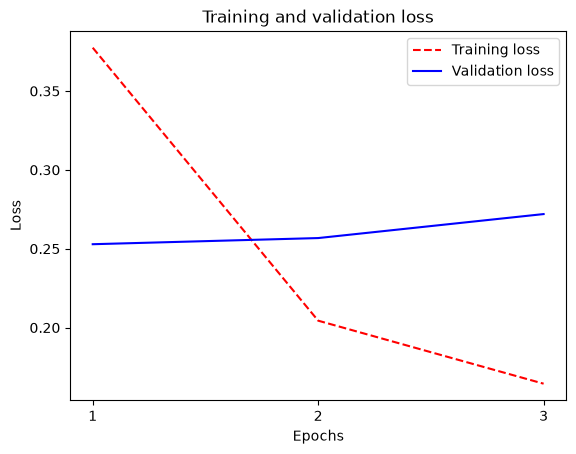

In [41]:
import matplotlib.pyplot as plt

history_dict = history.history
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "r--", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Loss")
plt.legend()
plt.show()

In [42]:
test_loss, test_accuracy = model.evaluate(
    tf_sequence_test_ds,
    verbose=1
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

60/60 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - accuracy: 0.9141 - loss: 0.2615
Test loss: 0.2615
Test accuracy: 91.41%
